# Part 2: NER Using Feed-Forward Neural Network

Uses the word embeddings learned in Part 1 (Skip-Gram with Negative Sampling).

Pipeline:
1. Load embeddings & vocab saved by Part 1
2. Build token-level dataset from CoNLL-2003 (train / val / test)
3. Train a Feed-Forward Neural Network (FFNN)
4. Evaluate: accuracy, precision, recall, F1-score
5. Plot: loss curves, confusion matrix, per-class F1

## 1. Imports

In [1]:
import numpy as np
import re
import pickle
import matplotlib.pyplot as plt
import seaborn as sns
from datasets import load_dataset
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix,
)

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

/Users/laila/.pyenv/versions/3.10.13/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 2. Load Embeddings and Vocab from Part 1

In [2]:
#Load embeddings & vocab from Part 1
embeddings = np.load('word_embeddings.npy')     # (VOCAB_SIZE, EMBED_DIM)
with open('vocab.pkl', 'rb') as f:
    vocab_data = pickle.load(f)
word2idx = vocab_data['word2idx']
idx2word = vocab_data['idx2word']
EMBED_DIM  = embeddings.shape[1]
 
print(f'Embeddings loaded: {embeddings.shape}')
print(f'Vocabulary size  : {len(word2idx)}')
print(f'Embedding dim     : {EMBED_DIM}')

Embeddings loaded: (13836, 100)
Vocabulary size  : 13836
Embedding dim     : 100


## 3. Dataset Loading & Preprocessing

preprocess_token must be identical to the one used in Part 1 so that the vocabulary lookup is consistent.

In [3]:
dataset = load_dataset('lhoestq/conll2003')

LABEL_LIST = ["O", "B-PER", "I-PER", "B-ORG", "I-ORG", "B-LOC", "I-LOC", "B-MISC", "I-MISC"]
NUM_LABELS = len(LABEL_LIST)

print(f'Dataset splits: { {k: len(v) for k, v in dataset.items()} }')
print(f'NER labels ({NUM_LABELS}): {LABEL_LIST}')

Dataset splits: {'train': 14041, 'validation': 3250, 'test': 3453}
NER labels (9): ['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC', 'B-MISC', 'I-MISC']


In [4]:
def preprocess_token(token: str) -> str:

    # Lowercase and remove non-alphanumeric characters except hyphens.
    token = token.lower()
    token = re.sub(r"[^a-z0-9\-]", "", token)
    return token if len(token) > 0 else None # Returns None for tokens that are purely punctuation/numbers.

In [5]:
def get_embedding(word):
    word = preprocess_token(word)
    if word and word in word2idx:
        return embeddings[word2idx[word]]
    return np.zeros(EMBED_DIM)

In [6]:
def build_split(split_name: str):

    X_list = []
    y_list = []
    
    for example in dataset[split_name]:
        tokens = example['tokens']
        tags   = example['ner_tags']
        
        # Get embeddings for each token in the sentence
        for t, tag in zip(tokens, tags):
            vec = get_embedding(t)
            X_list.append(vec)
            y_list.append(tag)
            
    # simple list of vectors and a simple list of integers
    X = np.array(X_list, dtype=np.float32)
    y = np.array(y_list, dtype=np.int64)
    return X, y #X : list of np.ndarray, each shape (seq_len, EMBED_DIM)
     #y : list of np.ndarray, each shape (seq_len,)  int labels

In [7]:
X_train, y_train = build_split('train')
X_val,   y_val   = build_split('validation')
X_test,  y_test  = build_split('test')
print(f'  Train : {len(X_train)} sentences')
print(f'  Val   : {len(X_val)} sentences')
print(f'  Test  : {len(X_test)} sentences')

  Train : 203621 sentences
  Val   : 51362 sentences
  Test  : 46435 sentences


## 4. Move Data to Device

In [8]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f'Using device: {device}')

X_train = torch.from_numpy(X_train).to(device)
y_train = torch.from_numpy(y_train).to(device)

X_val = torch.from_numpy(X_val).to(device)
y_val = torch.from_numpy(y_val).to(device)

X_test = torch.from_numpy(X_test).to(device)
y_test = torch.from_numpy(y_test).to(device)

Using device: cpu


## 5. Model Definition

Architecture: Embedding(100) → FC(512) → ReLU → Dropout(0.4) → FC(128) → ReLU → Dropout(0.4) → FC(9)

In [9]:
class NER_FFNN(nn.Module):
    def __init__(self, embedding_dim, num_classes):
        super().__init__()
        self.fc1 = nn.Linear(embedding_dim, 512)
        self.relu1 = nn.ReLU()
        self.dropout1 = nn.Dropout(0.4)
        self.fc2 = nn.Linear(512, 128)
        self.relu2 = nn.ReLU()
        self.dropout2 = nn.Dropout(0.4)
        self.fc3 = nn.Linear(128, num_classes)

    def forward(self, x):
        x = self.dropout1(self.relu1(self.fc1(x)))
        x = self.dropout2(self.relu2(self.fc2(x)))
        return self.fc3(x)

In [10]:
model = NER_FFNN(embedding_dim=100, num_classes=NUM_LABELS).to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

num_epochs = 30
batch_size = 512

total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'Model parameters: {total_params:,}')
print(model)

Model parameters: 118,537
NER_FFNN(
  (fc1): Linear(in_features=100, out_features=512, bias=True)
  (relu1): ReLU()
  (dropout1): Dropout(p=0.4, inplace=False)
  (fc2): Linear(in_features=512, out_features=128, bias=True)
  (relu2): ReLU()
  (dropout2): Dropout(p=0.4, inplace=False)
  (fc3): Linear(in_features=128, out_features=9, bias=True)
)


## 6. Training Loop

In [11]:
def train_epoch(X, y):
    model.train()
    total_loss = 0

    indices = torch.randperm(X.size(0))

    for i in range(0, X.size(0), batch_size):
        batch_idx = indices[i:i+batch_size]

        xb = X[batch_idx]
        yb = y[batch_idx]

        optimizer.zero_grad()

        outputs = model(xb)
        loss = criterion(outputs, yb)

        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    return total_loss / (X.size(0) // batch_size)

In [12]:
def evaluate_loss(X, y):
    model.eval()
    total_loss = 0
    with torch.no_grad():
        for i in range(0, X.size(0), batch_size):
            xb = X[i:i+batch_size]
            yb = y[i:i+batch_size]
            outputs = model(xb)
            loss = criterion(outputs, yb)
            total_loss += loss.item()
    return total_loss / (X.size(0) // batch_size)

In [13]:
train_losses, val_losses = [], []

for epoch in range(1, num_epochs + 1):
    train_loss = train_epoch(X_train, y_train)
    val_loss = evaluate_loss(X_val, y_val)
    train_losses.append(train_loss)
    val_losses.append(val_loss)
    
    print(f"Epoch {epoch+1} | Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f}")

Epoch 2 | Train Loss: 0.5694 | Val Loss: 0.4234
Epoch 3 | Train Loss: 0.4314 | Val Loss: 0.3919
Epoch 4 | Train Loss: 0.4102 | Val Loss: 0.3820
Epoch 5 | Train Loss: 0.3974 | Val Loss: 0.3722
Epoch 6 | Train Loss: 0.3865 | Val Loss: 0.3645
Epoch 7 | Train Loss: 0.3773 | Val Loss: 0.3591
Epoch 8 | Train Loss: 0.3699 | Val Loss: 0.3513
Epoch 9 | Train Loss: 0.3621 | Val Loss: 0.3463
Epoch 10 | Train Loss: 0.3567 | Val Loss: 0.3443
Epoch 11 | Train Loss: 0.3504 | Val Loss: 0.3400
Epoch 12 | Train Loss: 0.3452 | Val Loss: 0.3400
Epoch 13 | Train Loss: 0.3389 | Val Loss: 0.3333
Epoch 14 | Train Loss: 0.3343 | Val Loss: 0.3309
Epoch 15 | Train Loss: 0.3280 | Val Loss: 0.3287
Epoch 16 | Train Loss: 0.3224 | Val Loss: 0.3304
Epoch 17 | Train Loss: 0.3190 | Val Loss: 0.3222
Epoch 18 | Train Loss: 0.3154 | Val Loss: 0.3232
Epoch 19 | Train Loss: 0.3100 | Val Loss: 0.3192
Epoch 20 | Train Loss: 0.3066 | Val Loss: 0.3185
Epoch 21 | Train Loss: 0.3036 | Val Loss: 0.3192
Epoch 22 | Train Loss: 0.300

## 7. Loss Curves

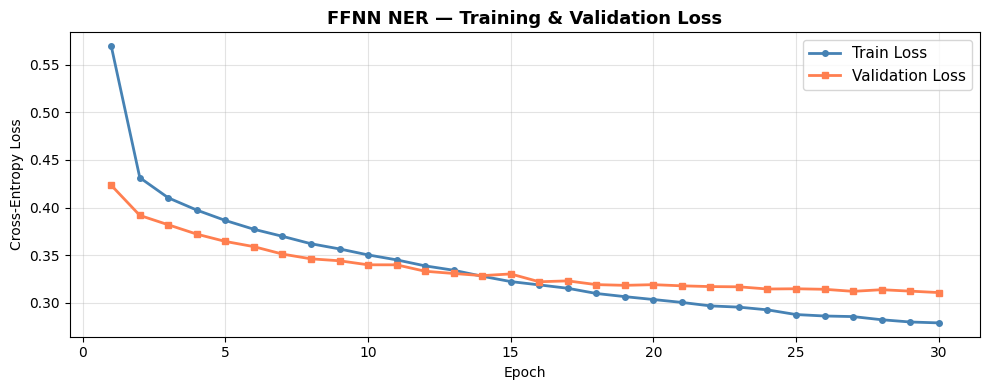

Figure saved: ffnn_loss_curves.png


In [14]:
epochs = range(1, num_epochs + 1)

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(epochs, train_losses, marker='o', markersize=4, linewidth=2,
        color='steelblue', label='Train Loss')
ax.plot(epochs, val_losses,   marker='s', markersize=4, linewidth=2,
        color='coral',     label='Validation Loss')
ax.set_title('FFNN NER — Training & Validation Loss', fontsize=13, fontweight='bold')
ax.set_xlabel('Epoch')
ax.set_ylabel('Cross-Entropy Loss')
ax.legend(fontsize=11)
ax.grid(True, alpha=0.35)
plt.tight_layout()
plt.savefig('ffnn_loss_curves.png', dpi=150)
plt.show()
print('Figure saved: ffnn_loss_curves.png')

## 8. Evaluation

In [15]:
def get_predictions(X):
    model.eval()
    preds = []
    with torch.no_grad():
        for i in range(0, X.size(0), batch_size):
            out  = model(X[i:i + batch_size])
            preds.extend(torch.argmax(out, dim=1).cpu().numpy())
    return np.array(preds)


val_preds  = get_predictions(X_val)
test_preds = get_predictions(X_test)

y_val_np  = y_val.cpu().numpy()
y_test_np = y_test.cpu().numpy()

# Validation 
val_acc = accuracy_score(y_val_np, val_preds)
val_p, val_r, val_f1, _ = precision_recall_fscore_support(
    y_val_np, val_preds, average='weighted', zero_division=0
)
print(f'Validation - Accuracy: {val_acc:.4f}  F1: {val_f1:.4f}')

# Test
acc       = accuracy_score(y_test_np, test_preds)
p, r, f1, _ = precision_recall_fscore_support(y_test_np, test_preds,
                                               average='weighted', zero_division=0)
print('\n' + '=' * 45)
print('      FFNN - Test Set Results')
print('=' * 45)
print(f'  Accuracy  : {acc:.4f}')
print(f'  Precision : {p:.4f}')
print(f'  Recall    : {r:.4f}')
print(f'  F1-score  : {f1:.4f}')
print('=' * 45)

Validation - Accuracy: 0.9164  F1: 0.9057

      FFNN - Test Set Results
  Accuracy  : 0.8993
  Precision : 0.8834
  Recall    : 0.8993
  F1-score  : 0.8855


### 8.1 Per-Class Classification Report

In [16]:
print(classification_report(
    y_test_np, test_preds,
    target_names=LABEL_LIST,
    zero_division=0
))

              precision    recall  f1-score   support

           O       0.93      0.99      0.96     38323
       B-PER       0.65      0.51      0.57      1617
       I-PER       0.42      0.21      0.28      1156
       B-ORG       0.72      0.48      0.58      1661
       I-ORG       0.69      0.20      0.30       835
       B-LOC       0.77      0.75      0.76      1668
       I-LOC       0.71      0.46      0.56       257
      B-MISC       0.80      0.53      0.63       702
      I-MISC       0.56      0.41      0.47       216

    accuracy                           0.90     46435
   macro avg       0.69      0.50      0.57     46435
weighted avg       0.88      0.90      0.89     46435



### 8.2 Confusion Matrix

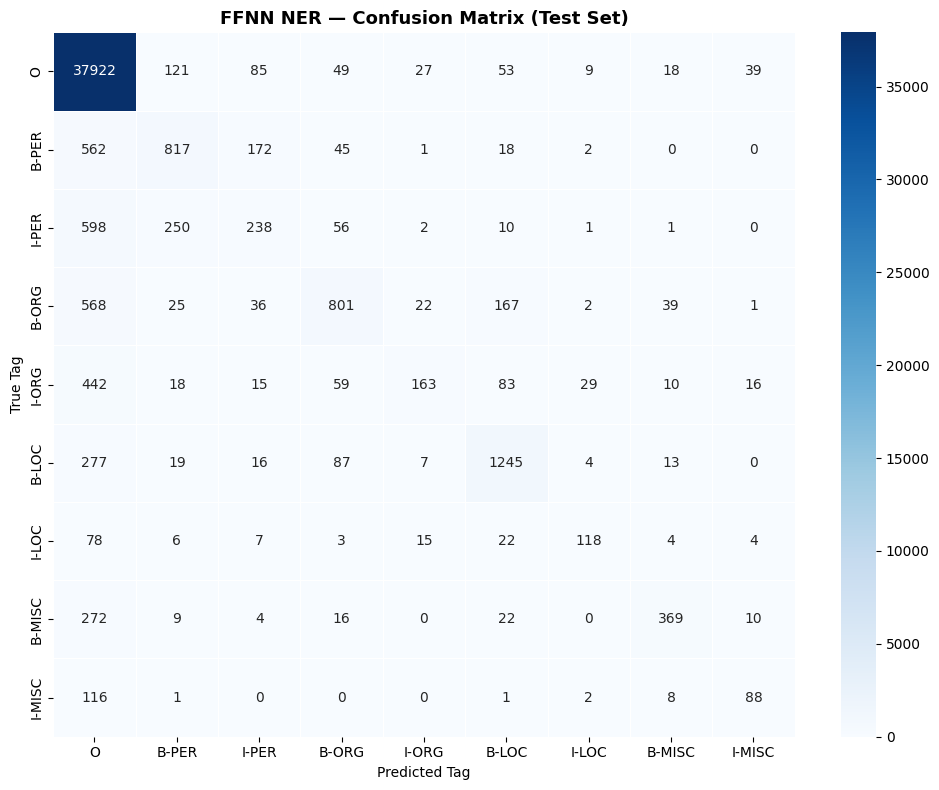

Figure saved: ffnn_confusion_matrix.png


In [17]:
cm = confusion_matrix(y_test_np, test_preds)

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(
    cm,
    annot=True, fmt='d',
    xticklabels=LABEL_LIST, yticklabels=LABEL_LIST,
    cmap='Blues', linewidths=0.5,
    ax=ax
)
ax.set_title('FFNN NER — Confusion Matrix (Test Set)', fontsize=13, fontweight='bold')
ax.set_xlabel('Predicted Tag')
ax.set_ylabel('True Tag')
plt.tight_layout()
plt.savefig('ffnn_confusion_matrix.png', dpi=150)
plt.show()
print('Figure saved: ffnn_confusion_matrix.png')

### 8.3 Per-Class F1 Score Bar Chart

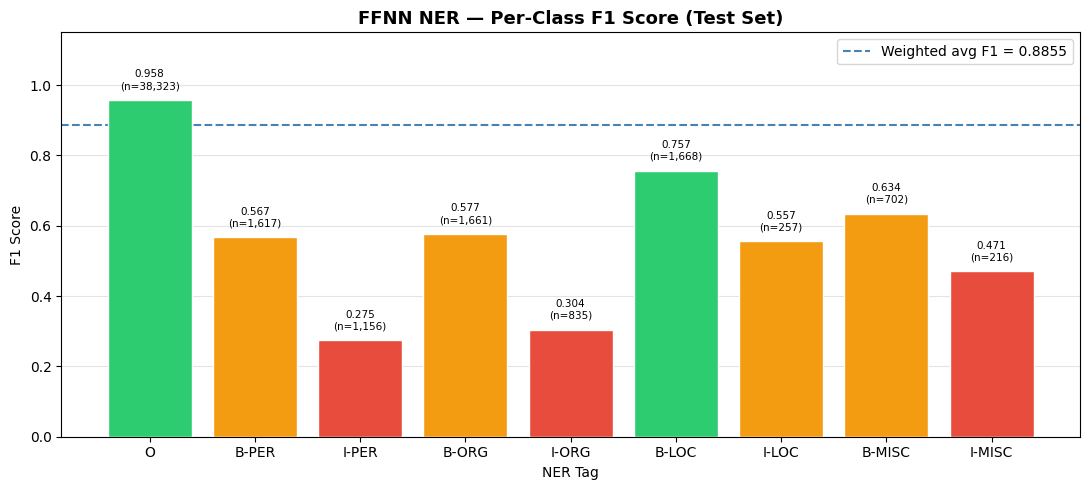

Figure saved: ffnn_f1_per_class.png


In [18]:
_, _, f1_per_class, support = precision_recall_fscore_support(
    y_test_np, test_preds,
    labels=list(range(NUM_LABELS)),
    zero_division=0
)

fig, ax = plt.subplots(figsize=(11, 5))
colors = ['#e74c3c' if s < 0.5 else '#f39c12' if s < 0.75 else '#2ecc71'
          for s in f1_per_class]
bars = ax.bar(LABEL_LIST, f1_per_class, color=colors, edgecolor='white', zorder=3)
ax.axhline(f1, color='steelblue', linestyle='--', linewidth=1.5,
           label=f'Weighted avg F1 = {f1:.4f}')
ax.set_ylim(0, 1.15)
ax.set_title('FFNN NER — Per-Class F1 Score (Test Set)', fontsize=13, fontweight='bold')
ax.set_xlabel('NER Tag')
ax.set_ylabel('F1 Score')
ax.legend(fontsize=10)
ax.grid(axis='y', alpha=0.35, zorder=0)

for bar, score, sup in zip(bars, f1_per_class, support):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.025,
            f'{score:.3f}\n(n={int(sup):,})', ha='center', va='bottom', fontsize=7.5)

plt.tight_layout()
plt.savefig('ffnn_f1_per_class.png', dpi=150)
plt.show()
print('Figure saved: ffnn_f1_per_class.png')

## 9. Summary

| Component | Details |
|---|---|
| Input | Word2Vec embeddings from Part 1 (dim = 100) |
| Architecture | FFNN: 100 → 512 → 128 → 9 |
| Activations | ReLU + Dropout(0.4) |
| Optimiser | Adam (lr = 0.001) |
| Loss | Cross-Entropy |
| Epochs | 30 |
| Batch size | 512 |
| Validation | Loss monitored each epoch (no weight updates on val) |
| Metrics | Accuracy, Precision, Recall, F1-score (weighted) |